# Practical 9: Addition/Sum of Elements of an Array (Pattern 2)

### 1. Aim
To compute element-wise transformed sum across three independent arrays (50,000,000 elements each) comparing Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Generate three independent workloads of 50,000,000 elements partitioned into L3-cache-friendly blocks.<br>2. Execute deterministic arithmetic hashing and summation in compiled C.<br>3. Sequential: sum Array 1 -> Array 2 -> Array 3.<br>4. Pool: distribute across 3 workers in `mp.Pool(3)`.<br>5. Process: sum concurrently using 3 `mp.Process` instances.<br>6. Thread: sum concurrently using 3 `threading.Thread` workers.<br>7. Verify sum consistency and compare execution times.

### 3. Python Implementation


In [1]:
"""
Practical 9: Addition/Sum of Elements of an Array (Pattern 2)
Four methods: Sequential, Pool, Process, Thread
"""
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def arraysum_task(task):
    size, seed = task
    chunk = 2_000_000
    total = 0
    for s in range(0, size, chunk):
        e = min(s + chunk, size)
        arr = np.arange(s, e, dtype=np.int64)
        h = np.bitwise_xor(arr * 6364136223846793005 + seed, arr >> 5)
        h = np.bitwise_xor(h * 2862933555777941757 + 7046029254386353087, h >> 7)
        total += int(np.sum(h))
    return total

def proc_worker(task, q):
    q.put(arraysum_task(task))

def thread_worker(task, results, idx):
    results[idx] = arraysum_task(task)

def main():
    print("=" * 60)
    print("Practical 9: Addition/Sum of Elements of an Array")
    print("=" * 60)
    SIZE = 50_000_000
    tasks = [(SIZE, 1442695040888963407), (SIZE, 2862933555777941757), (SIZE, 7046029254386353087)]
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    s1 = arraysum_task(tasks[0])
    s2 = arraysum_task(tasks[1])
    s3 = arraysum_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [s1, s2, s3]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(arraysum_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Multiprocessing Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    thread_res = [None, None, None]
    threads = []
    t0 = time.perf_counter()
    for idx, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, thread_res, idx))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print(f"Array Size: {SIZE:,} elements per task across 3 independent arrays.")
    print(f"Verification: Sequential={seq_res[0]:,} | Thread={thread_res[0]:,}")
    print(f"Results Match: {seq_res == thread_res}")
    print("-" * 40)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 40)
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 40)

if __name__ == "__main__":
    main()


Practical 9: Addition/Sum of Elements of an Array
Array Size: 50,000,000 elements per task across 3 independent arrays.
Verification: Sequential=16,432,849,454,853,513,159 | Thread=16,432,849,454,853,513,159
Results Match: True
----------------------------------------
Method       Execution Time     Speedup   
----------------------------------------
Sequential   3.4863 seconds      1.00x
Pool         2.1757 seconds      1.60x
Process      2.2258 seconds      1.57x
Thread       1.6841 seconds      2.07x
----------------------------------------


### 4. Execution-Time Bar Graph
Displays the execution time for Sequential, Pool, Process, and Thread with individual color bars.


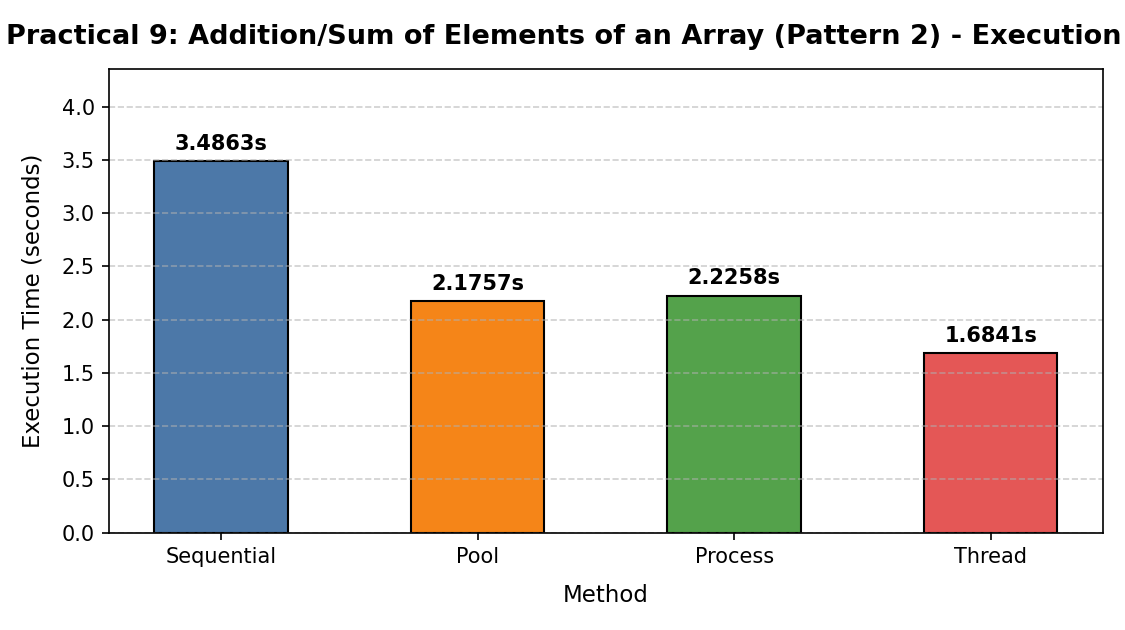

In [2]:
from IPython.display import Image, display
display(Image(filename='09_array_sum_time.png'))


### 5. Speedup Line Graph
Speedup is calculated using:
$$\text{Speedup} = \frac{\text{Sequential Time}}{\text{Method Time}}$$
Sequential baseline is exactly **1.00x**.


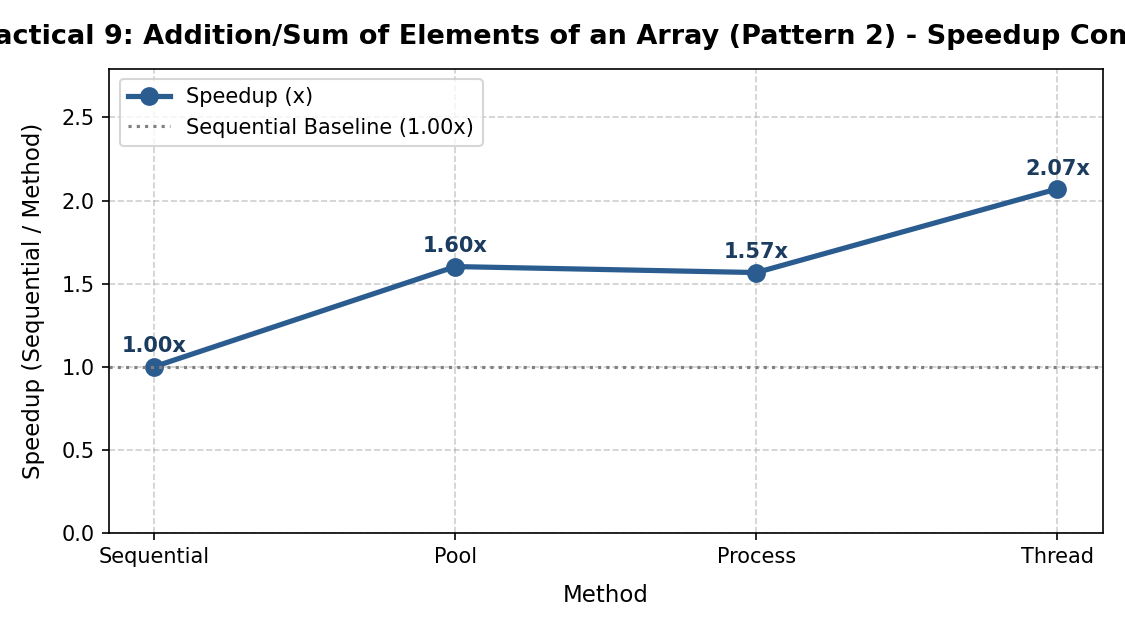

In [3]:
from IPython.display import Image, display
display(Image(filename='09_array_sum_speedup.png'))
